In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def linear_f(x,w,b):
    #Multivariate linear function
    #return vector of y predict
    #[y1,y2,y4] = #[x1w1 +b ,x2w2+b,x3w3+b..]

    return x @ w + b

def mse_loss(x,y,w,b):
    #loss per sample
    #return loss vector
    y_pred = linear_f(x,w,b)
    return 0.5 * (y - y_pred) ** 2

def grad_w_mse(x,y,w,b):

    return (linear_f(x,w,b)-y) * x

def grad_b_mse(x,y,w,b):

    return (linear_f(x,w,b)-y) * 1


def Decay_Gradient_decent(x,y,learning_rate,batch_size,epochs,seed = None,grad_reduce="mean",decay=0.9):
    """
    Gradient descent algorithm to optimize the weight and bias
    :param x: input data
    :param y: true labels
    :param learning_rate: learning rate for gradient descent
    :param batch_size: size of each batch for mini-batch gradient descent
    :param epochs: number of iterations for gradient descent
    :return: optimized weight and bias
    """

    #N  is number of data, D is dimention of x
    N,D = x.shape
    
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(D)
    b = rng.standard_normal()

    history = {'w': [w], 'b': [b], 'loss': [np.mean(mse_loss(x,y,w,b))],'lr':[learning_rate]}

    points = 0

    for epoch in range(epochs):
        #suffle data with idx
        idx = rng.permutation(N)
        #idx is array of suffle number between 0 ~ N 
        
        for start in range(0,N,batch_size):
            #from 0 ~ N step of batch_size
            
            batch = idx[start:start+batch_size]

            #dw => 0 vector sizeOF D
            #db = 0
            dw,db = np.zeros(D),0.0

            for j in batch :
                dw = dw + grad_w_mse(x[j],y[j],w,b)
                db = db + grad_b_mse(x[j],y[j],w,b)
            if grad_reduce == "mean":
                dw /= len(batch)
                db /= len(batch)

            w = w - learning_rate*dw
            b = b - learning_rate*db

            loss = np.mean(mse_loss(x,y,w,b))
            history['w'].append(w.copy())
            history['b'].append(b)
            history['loss'].append(loss)
            history['lr'].append(learning_rate)

            print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}, "
            f"w: {np.round(w, 3)}, b: {b:.4f}")
            
        learning_rate = learning_rate*decay

    return history




In [ ]:
def Decay_Gradient_decent2(x, y, learning_rate, batch_size, epochs, seed=None,
                           grad_reduce="mean", decay=0.9,
                           decay_step=0.01, decay_min=0.5):
    """
    에폭마다 lr *= decay 를 적용하고, decay 자체도 decay_step씩 줄여가는 버전
    (decay는 decay_min 아래로 내려가지 않도록 하한 설정)
    decay_step=0 이면 기존 고정 decay 방식과 동일
    """
    N, D = x.shape
    rng = np.random.default_rng(seed)
    w = rng.standard_normal(D)
    b = rng.standard_normal()

    history = {'w': [w.copy()], 'b': [b],
               'loss': [np.mean(mse_loss(x, y, w, b))],
               'lr': [learning_rate], 'decay': [decay]}

    for epoch in range(epochs):
        idx = rng.permutation(N)

        for start in range(0, N, batch_size):
            batch = idx[start:start + batch_size]
            dw, db = np.zeros(D), 0.0
            for j in batch:
                dw += grad_w_mse(x[j], y[j], w, b)
                db += grad_b_mse(x[j], y[j], w, b)
            if grad_reduce == "mean":
                dw /= len(batch); db /= len(batch)

            w = w - learning_rate * dw
            b = b - learning_rate * db

            history['w'].append(w.copy())
            history['b'].append(b)
            history['loss'].append(np.mean(mse_loss(x, y, w, b)))
            history['lr'].append(learning_rate)
            history['decay'].append(decay)

        print(f"Epoch {epoch+1}/{epochs}, Loss: {history['loss'][-1]:.4f}, "
              f"lr: {learning_rate:.5f}, decay: {decay:.2f}")

        learning_rate *= decay                       # 먼저 현재 decay로 lr 감쇠
        decay = max(decay - decay_step, decay_min)   # 그 다음 decay를 더 강하게 (하한 있음)

    return history

In [41]:
import seaborn as sns

df = sns.load_dataset("penguins").dropna()
X_raw = df[["flipper_length_mm", "bill_length_mm"]].values
y_raw = df["body_mass_g"].values

X = (X_raw - X_raw.mean(0)) / X_raw.std(0)
Y = (y_raw - y_raw.mean()) / y_raw.std()

# 해석해 (기준값)
A = np.c_[X, np.ones(len(X))]
w_star = np.linalg.lstsq(A, Y, rcond=None)[0]       # [w1, w2, b]
loss_star = np.mean(0.5 * (Y - A @ w_star) ** 2)    # 도달 가능한 최소 loss
print("해석해 [w1, w2, b]:", w_star, " 최소 loss:", loss_star)

decays = [1.0, 0.9, 0.7, 0.5, 0.1]
results = {}
for decay in decays:
    results[decay] = Decay_Gradient_decent(
        X, Y, learning_rate=0.05, batch_size=16, epochs=30, seed=42, decay=decay)

해석해 [w1, w2, b]: [ 8.50984846e-01  3.36766189e-02 -2.49443373e-16]  최소 loss: 0.11862873318098274
Epoch 1/30, Loss: 1.2504, w: [ 0.377 -0.947], b: 0.6866
Epoch 1/30, Loss: 1.1043, w: [ 0.422 -0.889], b: 0.6474
Epoch 1/30, Loss: 0.9423, w: [ 0.465 -0.81 ], b: 0.6012
Epoch 1/30, Loss: 0.8248, w: [ 0.519 -0.759], b: 0.5738
Epoch 1/30, Loss: 0.7366, w: [ 0.553 -0.709], b: 0.5527
Epoch 1/30, Loss: 0.6881, w: [ 0.583 -0.69 ], b: 0.5393
Epoch 1/30, Loss: 0.6325, w: [ 0.61  -0.662], b: 0.5177
Epoch 1/30, Loss: 0.5520, w: [ 0.646 -0.611], b: 0.4868
Epoch 1/30, Loss: 0.4753, w: [ 0.699 -0.557], b: 0.4732
Epoch 1/30, Loss: 0.4057, w: [ 0.74  -0.507], b: 0.4366
Epoch 1/30, Loss: 0.3657, w: [ 0.76  -0.475], b: 0.4082
Epoch 1/30, Loss: 0.3357, w: [ 0.778 -0.447], b: 0.3902
Epoch 1/30, Loss: 0.2957, w: [ 0.805 -0.407], b: 0.3623
Epoch 1/30, Loss: 0.2771, w: [ 0.831 -0.388], b: 0.3575
Epoch 1/30, Loss: 0.2603, w: [ 0.847 -0.369], b: 0.3453
Epoch 1/30, Loss: 0.2436, w: [ 0.856 -0.353], b: 0.3204
Epoch 1

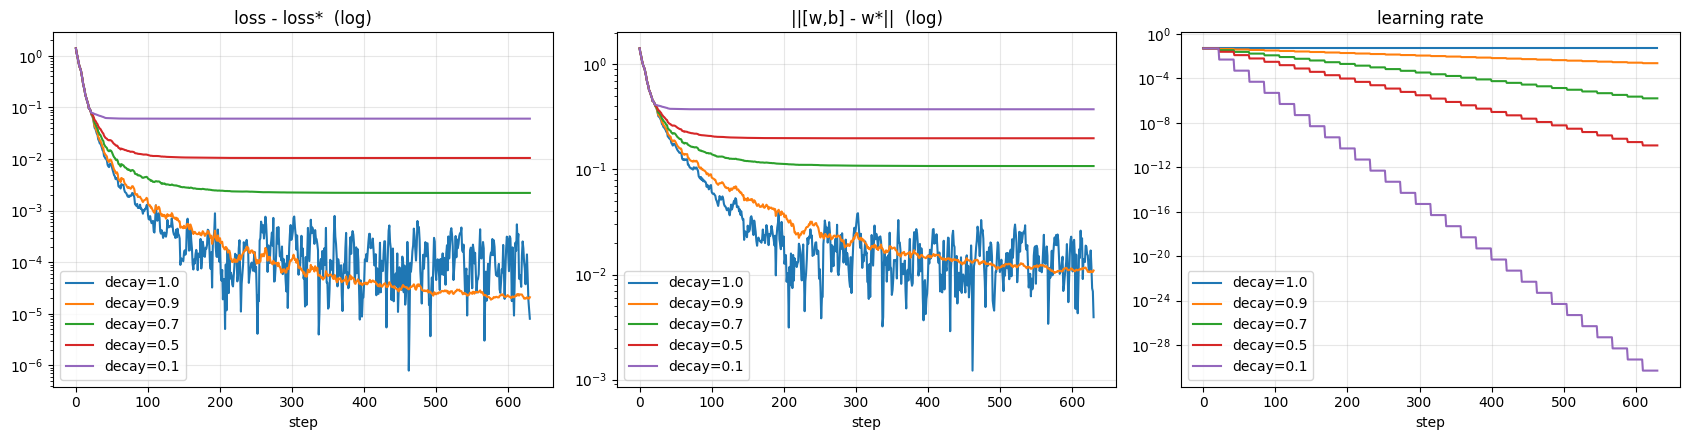

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for decay, h in results.items():
    L = np.array(h['loss'])
    W = np.array(h['w']); B = np.array(h['b'])
    err = np.linalg.norm(np.c_[W, B] - w_star, axis=1)    # 해석해와의 거리

    axes[0].plot(L - loss_star + 1e-12, label=f"decay={decay}")
    axes[1].plot(err + 1e-12, label=f"decay={decay}")
    axes[2].plot(h['lr'], label=f"decay={decay}")

axes[0].set_title("loss - loss*  (log)");  axes[0].set_yscale("log")
axes[1].set_title("||[w,b] - w*||  (log)"); axes[1].set_yscale("log")
axes[2].set_title("learning rate");         axes[2].set_yscale("log")
for ax in axes:
    ax.set_xlabel("step"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()